<a href="https://colab.research.google.com/github/iamttom/M18/blob/main/M24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# =========================
# 0) Imports e setup
# =========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.preprocessing import LabelEncoder

# Para exibirmos tudo
pd.set_option("display.max_columns", None)


In [2]:
# =========================
# 1) Carregamento da base
# =========================
# Opção A (recomendada no Colab): carrega do repositório do seaborn
import seaborn as sns
df = sns.load_dataset("penguins").copy()

# Renomeando para ficar igual ao enunciado (português)
df = df.rename(columns={
    "species": "species",
    "island": "island",
    "bill_length_mm": "bill_length_mm",
    "bill_depth_mm": "bill_depth_mm",
    "flipper_length_mm": "flipper_length_mm",
    "body_mass_g": "body_mass_g",
    "sex": "sex"
})

print(df.shape)
df.head()


(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


/tmp/ipython-input-1090056007.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=sorted(df["species"].dropna().unique()))


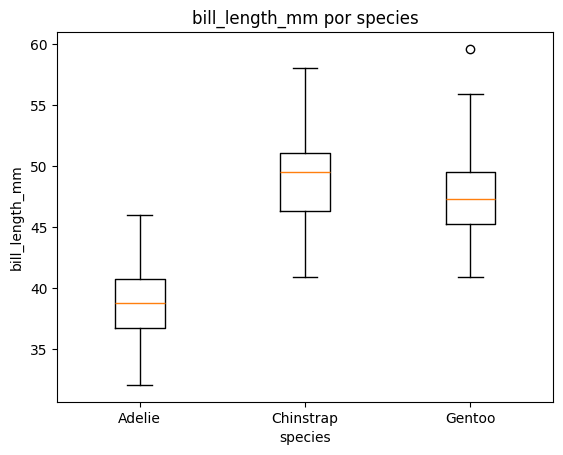

/tmp/ipython-input-1090056007.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=sorted(df["species"].dropna().unique()))


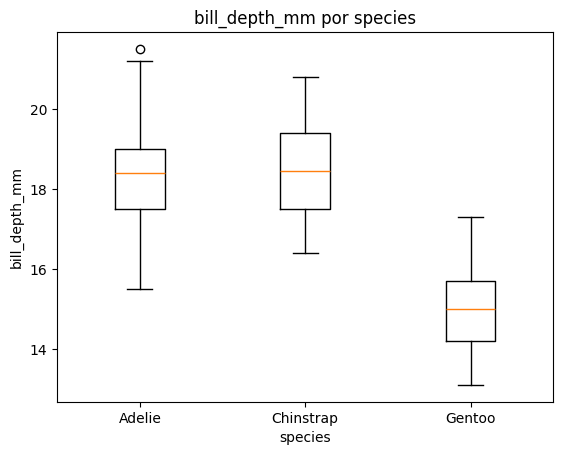

/tmp/ipython-input-1090056007.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=sorted(df["species"].dropna().unique()))


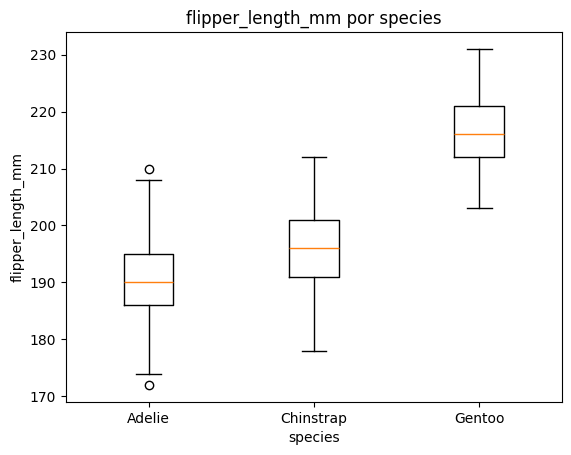

/tmp/ipython-input-1090056007.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=sorted(df["species"].dropna().unique()))


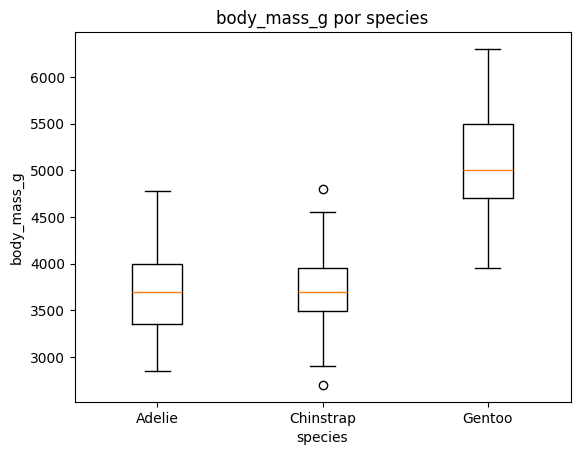

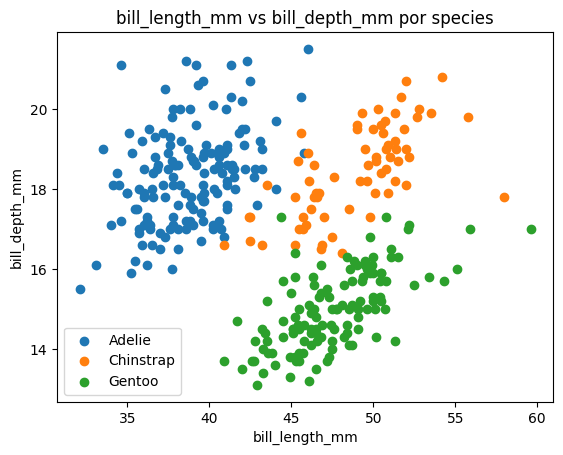

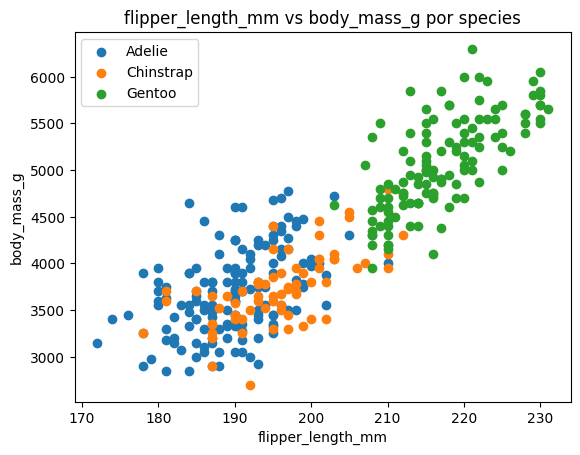

In [4]:
# =========================
# 1.1) Atributos numéricos por espécie (boxplots + dispersões)
# =========================
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

# Boxplots por espécie
for col in num_cols:
    plt.figure()
    # organização dos dados
    data = [df[df["species"]==s][col].dropna() for s in sorted(df["species"].dropna().unique())]
    plt.boxplot(data, labels=sorted(df["species"].dropna().unique()))
    plt.title(f"{col} por species")
    plt.xlabel("species")
    plt.ylabel(col)
    plt.show()

# Dispersões úteis (sem seaborn)
plt.figure()
df_cleaned = df[num_cols + ["species"]].dropna()
for sp in sorted(df_cleaned["species"].unique()):
    sub = df_cleaned[df_cleaned["species"]==sp]
    plt.scatter(sub["bill_length_mm"], sub["bill_depth_mm"], label=sp)
plt.title("bill_length_mm vs bill_depth_mm por species")
plt.xlabel("bill_length_mm")
plt.ylabel("bill_depth_mm")
plt.legend()
plt.show()

plt.figure()
df_cleaned = df[num_cols + ["species"]].dropna()
for sp in sorted(df_cleaned["species"].unique()):
    sub = df_cleaned[df_cleaned["species"]==sp]
    plt.scatter(sub["flipper_length_mm"], sub["body_mass_g"], label=sp)
plt.title("flipper_length_mm vs body_mass_g por species")
plt.xlabel("flipper_length_mm")
plt.ylabel("body_mass_g")
plt.legend()
plt.show()

sex,Female,Male
species,,
Adelie,73,73
Chinstrap,34,34
Gentoo,58,61


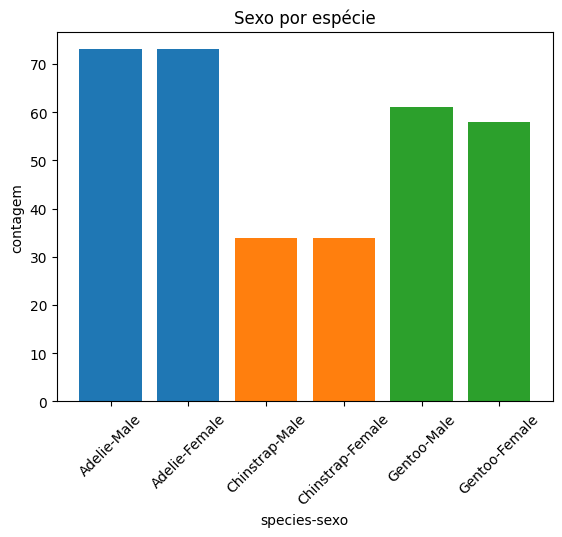

In [5]:
# =========================
# 1.2) Sexo por espécie (tabela + barra)
# =========================
ct_sex = pd.crosstab(df["species"], df["sex"])
display(ct_sex)

plt.figure()
for i, sp in enumerate(sorted(df["species"].dropna().unique())):
    counts = df[df["species"]==sp]["sex"].value_counts()
    plt.bar([f"{sp}-Male", f"{sp}-Female"], [counts.get("Male", 0), counts.get("Female", 0)])
plt.title("Sexo por espécie")
plt.xlabel("species-sexo")
plt.ylabel("contagem")
plt.xticks(rotation=45)
plt.show()


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


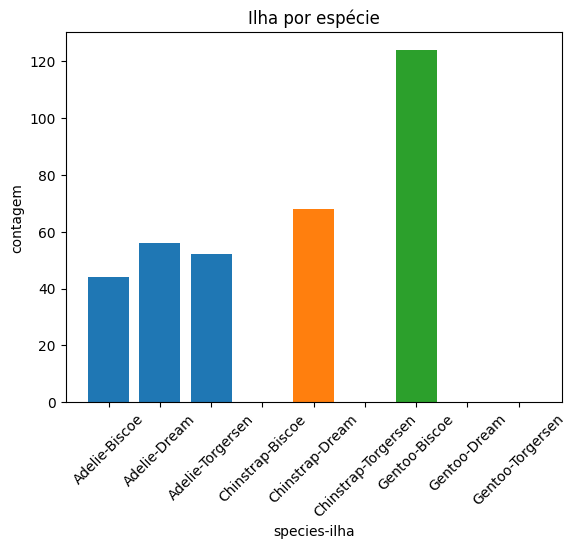

In [6]:
# =========================
# 1.3) Ilha por espécie (tabela + barra)
# =========================
ct_island = pd.crosstab(df["species"], df["island"])
display(ct_island)

plt.figure()
for sp in sorted(df["species"].dropna().unique()):
    counts = df[df["species"]==sp]["island"].value_counts()
    plt.bar([f"{sp}-Biscoe", f"{sp}-Dream", f"{sp}-Torgersen"],
            [counts.get("Biscoe", 0), counts.get("Dream", 0), counts.get("Torgersen", 0)])
plt.title("Ilha por espécie")
plt.xlabel("species-ilha")
plt.ylabel("contagem")
plt.xticks(rotation=45)
plt.show()


Os boxplots mostram que Gentoo tende a ter barbatana (flipper_length) e massa maiores; Adelie tem bicos mais curtos e profundos; Chinstrap exibe bico mais longo e profundo que Adelie, mas massa menor que Gentoo.

A relação flipper_length × body_mass separa bem Gentoo (região mais alta em ambos).

As tabelas/contagens indicam que a distribuição de sexos é semelhante dentro de cada espécie, e a variável island ajuda: Gentoo aparece majoritariamente em Biscoe, Chinstrap em Dream, enquanto Adelie está nas três ilhas — um bom sinal de poder preditivo.

In [8]:
# =========================
# 2.1) Tratamento de valores faltantes
# =========================
df_clean = df.copy()

# Numéricos -> mediana
for col in num_cols:
    med = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(med)

# Categóricos -> moda
for col in ["island", "sex"]:
    mode = df_clean[col].mode(dropna=True)[0]
    df_clean[col] = df_clean[col].fillna(mode)

# species (resposta) -> descartar linhas sem rótulo (normal em classificação)
df_clean = df_clean.dropna(subset=["species"]).reset_index(drop=True)

df_clean.isna().sum()


,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


In [9]:
# =========================
# 2.2) Codificação categórica (nominais)
# =========================
le_island = LabelEncoder()
le_sex = LabelEncoder()

df_clean["island_nom"] = le_island.fit_transform(df_clean["island"])
df_clean["sex_nom"]    = le_sex.fit_transform(df_clean["sex"])

# (Não criamos *_ord pois não há variáveis ordinais)
df_clean[["island", "island_nom", "sex", "sex_nom"]].head()


,island,island_nom,sex,sex_nom
0,Torgersen,2,Male,1
1,Torgersen,2,Female,0
2,Torgersen,2,Female,0
3,Torgersen,2,Male,1
4,Torgersen,2,Female,0


In [10]:
# =========================
# 2.3) Reorganizar e descartar originais
# =========================
# Mantemos 'species' como primeira coluna
cols_model = ["species", "bill_length_mm", "bill_depth_mm", "flipper_length_mm",
              "body_mass_g", "island_nom", "sex_nom"]

df_model = df_clean[cols_model].copy()
df_model.head()


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_nom,sex_nom
0,Adelie,39.10,18.7,181.0,3750.0,2,1
1,Adelie,39.50,17.4,186.0,3800.0,2,0
2,Adelie,40.30,18.0,195.0,3250.0,2,0
3,Adelie,44.45,17.3,197.0,4050.0,2,1
4,Adelie,36.70,19.3,193.0,3450.0,2,0


In [11]:
# =========================
# 2.4) Split 2/3 x 1/3
# =========================
X = df_model.drop(columns=["species"])
y = df_model["species"]  # scikit-learn aceita string como rótulo

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=1/3, random_state=42, stratify=y
)

X_train.shape, X_test.shape, y_train.value_counts(normalize=True), y_test.value_counts(normalize=True)


((229, 6),
 (115, 6),
 species
 Adelie       0.441048
 Gentoo       0.362445
 Chinstrap    0.196507
 Name: proportion, dtype: float64,
 species
 Adelie       0.443478
 Gentoo       0.356522
 Chinstrap    0.200000
 Name: proportion, dtype: float64)

Número de folhas da árvore treinada: 13


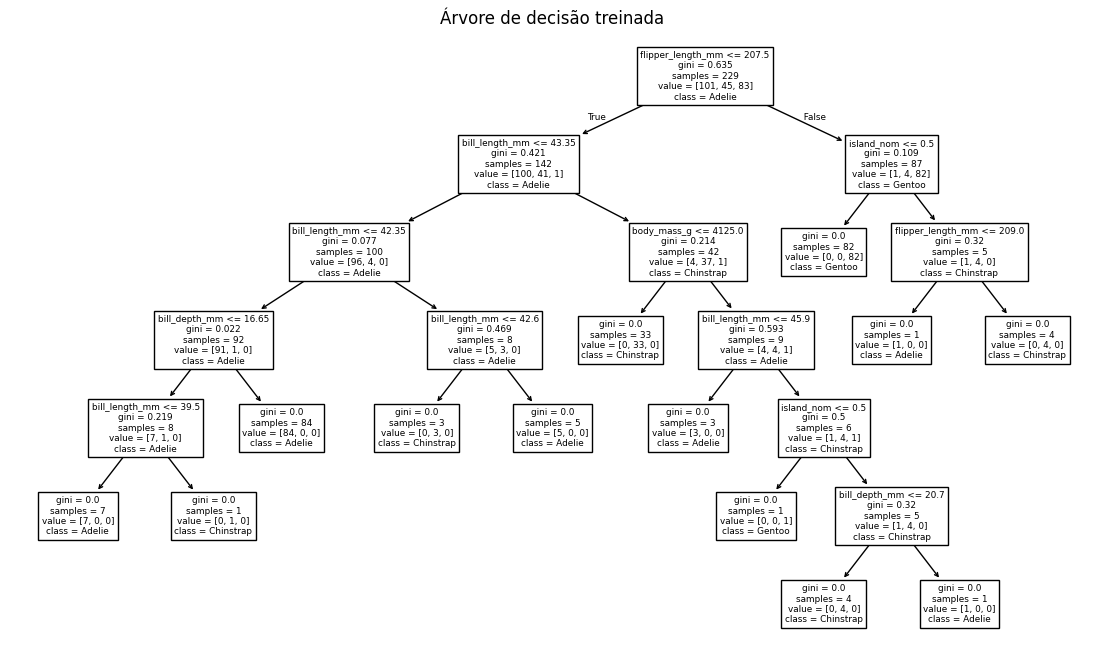

In [12]:
# =========================
# 3.1) Treinar árvore
# =========================
clf = DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    random_state=42
)
clf.fit(X_train, y_train)

# Número de folhas
n_leaves = clf.get_n_leaves()
print("Número de folhas da árvore treinada:", n_leaves)

# Gráfico da árvore
plt.figure(figsize=(14, 8))
plot_tree(
    clf,
    feature_names=X.columns.tolist(),
    class_names=sorted(y.unique()),
    filled=False,  # sem definir cores
    impurity=True,
    rounded=False
)
plt.title("Árvore de decisão treinada")
plt.show()


<Figure size 640x480 with 0 Axes>

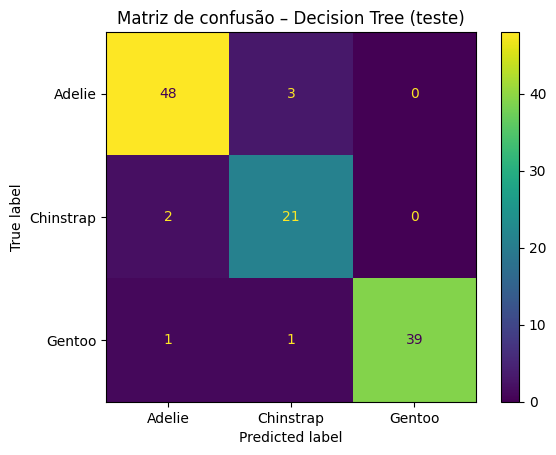

Acurácia no teste: 0.9391


In [13]:
# =========================
# 3.2) Avaliação
# =========================
y_pred = clf.predict(X_test)

# Matriz de confusão
cm = confusion_matrix(y_test, y_pred, labels=sorted(y.unique()))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y.unique()))
plt.figure()
disp.plot(values_format="d")
plt.title("Matriz de confusão – Decision Tree (teste)")
plt.show()

# Acurácia
acc = accuracy_score(y_test, y_pred)
print(f"Acurácia no teste: {acc:.4f}")


A matriz de confusão deve mostrar poucos erros; geralmente o modelo confunde alguns Adelie × Chinstrap quando medidas de bico são semelhantes.

A acurácia típica fica perto de 0.94–0.98 (referência ≈ 0.96). Se o seu valor variar um pouco, é normal — depende do random_state e da codificação.

In [14]:
# =========================
# 4) Predição para novo pinguim
# =========================
novo = pd.DataFrame([{
    "island": "Biscoe",
    "bill_length_mm": 38.2,
    "bill_depth_mm": 18.1,
    "flipper_length_mm": 185.0,
    "body_mass_g": 3950.0,
    "sex": "Male"
}])

# Preprocesso igual ao treino
novo["island_nom"] = le_island.transform(novo["island"])
novo["sex_nom"]    = le_sex.transform(novo["sex"])

X_novo = novo[["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g","island_nom","sex_nom"]]

pred = clf.predict(X_novo)[0]
pred


'Adelie'